# 01 · Datos — pasos 1 y 2 (¿hace falta ML? y datos)

**Proyecto final · Machine Learning · Universidad EIA**

> **La pregunta:** dado un vuelo, ¿cuántos minutos de retraso tendrá al llegar? &nbsp;→&nbsp; **regresión**

**Qué hace este notebook**

1. Ficha del problema y fuente de los datos.
2. Inventario de los CSV mensuales y qué columna cumple cada papel.
3. Lectura segura (todo como texto, tipos decididos por nosotros) y conversión a Parquet.
4. **Partición temporal** entrenamiento / prueba, *antes de medir nada*.
5. Exploración, solo con entrenamiento.
6. Regla a mano y línea base: **el número a vencer**.

| Lee | Produce |
|---|---|
| `data/raw/*.csv` | `data/interim/mensual/` (Parquet tipado, un archivo por mes) |
| | `data/interim/train/` y `data/interim/test/` (la prueba queda guardada hasta el notebook 05) |
| | `data/interim/train_muestra.parquet` (muestra reproducible para explorar y para la demo) |
| | `data/interim/resumen_01.json` (roles de columnas, corte, línea base) |
| | `docs/diccionario_borrador.csv` (para completar a mano) |

**Cómo usarlo:** `Restart & Run All`. La conversión a Parquet tarda varios minutos (son ~39 millones de filas). Lo único que hay que completar a mano es la tabla de la fuente (licencia y fecha de descarga) y revisar `docs/diccionario_borrador.csv`.

## Ficha del problema

| | |
|---|---|
| **Tipo** | Regresión |
| **Etiqueta** | minutos de retraso en la llegada (`arr_delay`; negativo = llegó antes de lo programado) |
| **Qué es una fila** | un vuelo programado |
| **Periodo** | enero 2021 – mayo 2026: 65 archivos mensuales, uno por mes |
| **Filas / columnas** | ≈ 39 millones de vuelos · 34 columnas (35 en algunos meses) |

### Momento de predicción: la decisión que define todo lo demás

La etiqueta se conoce al aterrizar. La pregunta es **qué sabemos cuando hacemos la predicción**:

- **`programacion`** — al programarse el vuelo (días antes): aerolínea, origen, destino, fecha, hora programada, distancia, duración programada. *Es la versión más exigente y la más honesta.*
- **`despegue`** — con el avión a punto de salir: además se conoce el retraso de salida, que explica casi todo el retraso de llegada.

Este notebook usa **`programacion`** (variable `MOMENTO_PREDICCION` en la configuración; si el grupo decide otro, se cambia ahí).

Todo lo que se conozca **después** del momento elegido es una **fuga** y no puede entrar como entrada (se revisa en el notebook 02).

## Fuente de los datos

Esta tabla es lo primero que se muestra en la exposición (con la página abierta). **✏️ Completen los dos campos marcados.**

| | |
|---|---|
| **Página** | https://www.kaggle.com/datasets/umerhafeezsiddiqui/2021-2026-us-flights |
| **Quién publica** | usuario de Kaggle `umerhafeezsiddiqui` |
| **Qué incluye** | un registro por vuelo de aerolíneas de EE. UU.: aeropuertos, horas programadas y reales, retrasos, cancelaciones y desvíos |
| **Origen probable** | la estructura de columnas (`dep_del15`, `taxi_out`, `wheels_off`, `cancellation_code`, `carrier_delay`…) coincide con la tabla *On-Time Performance* del Bureau of Transportation Statistics (BTS) de EE. UU. Confirmen en la descripción de la página si el publicador la transformó |
| **Licencia** | ✏️ copiar de la sección *License* de la página |
| **Descarga** | archivos CSV mensuales, `data/raw/`. ✏️ fecha de descarga |

## 0 · Configuración y decisiones del grupo

In [1]:
import json, re, time, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    import pyarrow  # motor de Parquet
except ImportError as e:
    raise ImportError("Falta pyarrow: instálenlo con  pip install pyarrow") from e

def _version(txt):
    return tuple(int(x) for x in re.findall(r"\d+", txt)[:3])

if _version(pyarrow.__version__) >= (21,) and _version(pd.__version__) < (2, 3, 2):
    raise RuntimeError("pandas < 2.3.2 no es compatible con pyarrow >= 21. Usen  pip install -U 'pandas>=2.3.2,<3'"
                       "  o bien  pip install 'pyarrow<21'")

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# ---------- rutas (funciona si el notebook está en la raíz o en notebooks/) ----------
RAIZ = Path(".") if Path("data/raw").exists() else Path("..")
RAW = RAIZ / "data" / "raw"
INTERIM = RAIZ / "data" / "interim"
MENSUAL, TRAIN, TEST = INTERIM / "mensual", INTERIM / "train", INTERIM / "test"
DOCS = RAIZ / "docs"
for p in (MENSUAL, TRAIN, TEST, DOCS):
    p.mkdir(parents=True, exist_ok=True)

# ---------- ✏️ decisiones del grupo ----------
SEED = 42
MOMENTO_PREDICCION = "programacion"   # "programacion" o "despegue" (ver ficha del problema)
FECHA_CORTE = "2026-01-01"            # desde esta fecha: prueba. Usen el día 1 de un mes.
N_MUESTRA = 500_000                   # filas de la muestra de entrenamiento (para explorar y para la demo)
UMBRAL_RETRASO = 15                   # minutos: referencia de "retraso" en las gráficas
TAM_TROZO = 200_000                   # filas por trozo al leer CSV grandes (bájenlo si les falta memoria)
SIN_FECHA_MAX = 0.001                 # fracción máxima tolerada de filas cuya fecha no se pueda leer (0,1 %)
COLUMNAS_MANUAL = {}                  # ej.: {"etiqueta": "ArrDelay"} si no se detecta sola
FORZAR_TEXTO = []                     # columnas que parecen número pero son códigos
FORZAR_NUMERICO = []                  # columnas que se leen como texto pero son cantidades

np.random.seed(SEED)
print(f"pandas {pd.__version__} · pyarrow {pyarrow.__version__}")
print(f"Raíz del proyecto: {RAIZ.resolve()}")
print(f"Momento de predicción: {MOMENTO_PREDICCION} · corte: {FECHA_CORTE} · semilla: {SEED}")

pandas 2.2.3 · pyarrow 20.0.0
Raíz del proyecto: /Users/santiagoespinel/Documents/ai-course/EIA/ML-final/Proyecto-final-Machine-Learning
Momento de predicción: programacion · corte: 2026-01-01 · semilla: 42


## 1 · Inventario de los archivos

Antes de leer nada en serio: ¿cuántos archivos hay, cuánto pesan, cuántas filas tienen y **tienen todos las mismas columnas**? Un mes con una columna renombrada rompe una unión sin avisar.

In [2]:
MESES_ARCH = {"jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6, "jul": 7, "aug": 8, "sep": 9,
              "oct": 10, "nov": 11, "dec": 12, "ene": 1, "abr": 4, "ago": 8, "dic": 12}

def periodo_de_archivo(nombre):
    """'Apr-2024.csv' -> Period('2024-04'). Si el nombre no dice el mes, devuelve None."""
    m = re.search(r"([A-Za-z]{3})[A-Za-z]*[-_ ]*((?:19|20)\d{2})", nombre)
    if m and m.group(1).lower() in MESES_ARCH:
        return pd.Period(year=int(m.group(2)), month=MESES_ARCH[m.group(1).lower()], freq="M")
    return None

archivos = sorted(RAW.glob("*.csv"), key=lambda p: (str(periodo_de_archivo(p.name) or "0000"), p.name))
assert archivos, f"No encontré CSV en {RAW.resolve()}"
PERIODOS = {p.name: periodo_de_archivo(p.name) for p in archivos}

def normalizar(nombre):
    """FL_DATE -> fl_date, CRSDepTime -> crs_dep_time, 'Unnamed: 5' -> unnamed_5"""
    n = re.sub(r"(?<=[A-Z])(?=[A-Z][a-z])", "_", str(nombre).strip())
    n = re.sub(r"(?<=[a-z0-9])(?=[A-Z])", "_", n)
    return re.sub(r"[^0-9A-Za-z]+", "_", n).strip("_").lower()

def es_basura(nombre):
    # columnas fantasma: sin nombre, 'unnamed_N' (comas finales) o de una sola letra
    return nombre.startswith("unnamed") or len(nombre) < 2

def contar_filas(ruta):
    n, ultimo = 0, b"\n"
    with open(ruta, "rb") as f:
        while bloque := f.read(1 << 24):
            n += bloque.count(b"\n")
            ultimo = bloque[-1:]
    return n - 1 + (ultimo != b"\n")          # restamos el encabezado

def leer_csv(ruta, **kw):
    # todo como texto y sin convertir "NA"/"None" en vacío: pandas no adivina nada
    return pd.read_csv(ruta, dtype=str, na_filter=False, encoding="utf-8-sig",
                       encoding_errors="replace", **kw)

def limpiar_columnas(df):
    df.columns = [normalizar(c) for c in df.columns]
    return df.loc[:, [not es_basura(c) for c in df.columns]]

filas, columnas_por_archivo = [], {}
for ruta in archivos:
    nombres = [normalizar(c) for c in leer_csv(ruta, nrows=0).columns]
    columnas_por_archivo[ruta.name] = [n for n in nombres if not es_basura(n)]
    filas.append({"archivo": ruta.name, "mes": str(PERIODOS[ruta.name] or "?"),
                  "MB": round(ruta.stat().st_size / 1e6, 1), "filas": contar_filas(ruta),
                  "columnas": len(columnas_por_archivo[ruta.name]),
                  "descartadas": ", ".join(repr(n) for n in nombres if es_basura(n))})
inventario = pd.DataFrame(filas)
display(inventario)
print(f"Total: {len(archivos)} archivos · {inventario.filas.sum():,} filas · {inventario.MB.sum():,.0f} MB")
print(f"Meses: {inventario.mes.iloc[0]} → {inventario.mes.iloc[-1]}")
faltan_nombre = [n for n, p in PERIODOS.items() if p is None]
print("✓ El nombre de cada archivo indica su mes (se usa para validar las fechas)." if not faltan_nombre
      else f"⚠️ No pude leer el mes en el nombre de: {faltan_nombre}")
conocidos = [p for p in PERIODOS.values() if p is not None]
if conocidos:
    esperados = pd.period_range(min(conocidos), max(conocidos), freq="M")
    meses_faltantes = [str(m) for m in esperados if m not in set(conocidos)]
    print("✓ No falta ningún mes en el rango." if not meses_faltantes else f"⚠️ Meses sin archivo: {meses_faltantes}")

# ¿todos los archivos traen las mismas columnas? (se compara con la combinación más común)
base_cols = list(Counter(tuple(c) for c in columnas_por_archivo.values()).most_common(1)[0][0])
distintos = False
for nombre, cols in columnas_por_archivo.items():
    faltan, sobran = set(base_cols) - set(cols), set(cols) - set(base_cols)
    if faltan or sobran:
        distintos = True
        print(f"ℹ️ {nombre}: le faltan {sorted(faltan)} y le sobran {sorted(sobran)}")
if distintos:
    print("Al unir los meses, la columna que un mes no trae queda vacía en ese mes.")
else:
    print("✓ Todos los archivos tienen exactamente las mismas columnas.")

,archivo,mes,MB,filas,columnas,descartadas
0,Jan-2021.csv,2021-01,66.1,379384,34,
1,Feb-2021.csv,2021-02,60.3,350170,34,
2,Mar-2021.csv,2021-03,81.3,467126,34,
3,Apr-2021.csv,2021-04,82.7,473936,34,
4,May-2021.csv,2021-05,91.0,520059,34,
5,Jun-2021.csv,2021-06,101.3,573779,34,
6,Jul-2021.csv,2021-07,108.8,615703,34,
7,Aug-2021.csv,2021-08,107.3,611494,34,
8,Sep-2021.csv,2021-09,99.2,567916,34,
9,Oct-2021.csv,2021-10,105.4,595373,34,


Total: 65 archivos · 39,073,000 filas · 5,922 MB
Meses: 2021-01 → 2026-05
✓ El nombre de cada archivo indica su mes (se usa para validar las fechas).
✓ No falta ningún mes en el rango.
ℹ️ Feb-2023.csv: le faltan [] y le sobran ['cancellation_code']
ℹ️ Mar-2023.csv: le faltan [] y le sobran ['cancellation_code']
ℹ️ Apr-2023.csv: le faltan [] y le sobran ['cancellation_code']
ℹ️ May-2023.csv: le faltan [] y le sobran ['cancellation_code']
ℹ️ Jun-2023.csv: le faltan [] y le sobran ['cancellation_code']
ℹ️ Mar-2025.csv: le faltan ['year'] y le sobran []
Al unir los meses, la columna que un mes no trae queda vacía en ese mes.


### Primer vistazo a un archivo

Las tres primeras filas, tal cual llegaron (como texto). Con esto se arma el diccionario: **qué significa cada columna y cuándo se conoce**.

In [3]:
vistazo = limpiar_columnas(leer_csv(archivos[0], nrows=3))
display(vistazo.T.rename(columns=lambda i: f"fila {i + 1}"))

,fila 1,fila 2,fila 3
year,2021,2021,2021
month,1,1,1
day_of_month,1,1,1
fl_date,1/1/2021 12:00:00 AM,1/1/2021 12:00:00 AM,1/1/2021 12:00:00 AM
op_unique_carrier,9E,9E,9E
tail_num,N131EV,N131EV,N131EV
op_carrier_fl_num,4656,4656,4889
origin_airport_id,10397,12448,10397
origin,ATL,JAN,ATL
dest_airport_id,12448,10397,11996


## 2 · ¿Qué columna cumple cada papel?

Los nombres de columna cambian de una fuente a otra (`ARR_DELAY`, `ArrDelay`, `arrival_delay`…). Aquí se detectan los papeles que necesita este notebook. **Revisen que la tabla sea correcta**; si algo está mal o falta, corríjanlo en `COLUMNAS_MANUAL` (celda de configuración) y vuelvan a correr.

In [4]:
todas = list(dict.fromkeys(c for cols in columnas_por_archivo.values() for c in cols))

CANDIDATOS = {
    "fecha":            ["fl_date", "flight_date", "flightdate", "date", "fecha"],
    "etiqueta":         ["arr_delay", "arrival_delay", "arrdelay"],
    "retraso_salida":   ["dep_delay", "departure_delay", "depdelay"],
    "cancelado":        ["cancelled", "canceled", "cancelado"],
    "desviado":         ["diverted", "desviado"],
    "aerolinea":        ["op_unique_carrier", "op_carrier", "reporting_airline", "unique_carrier",
                         "mkt_unique_carrier", "carrier", "airline", "airline_code"],
    "origen":           ["origin", "origin_airport", "origin_airport_code"],
    "destino":          ["dest", "destination", "dest_airport", "destination_airport"],
    "hora_prog_salida": ["crs_dep_time", "sched_dep_time", "scheduled_departure", "scheduled_dep_time", "crsdeptime"],
    "distancia":        ["distance"],
    "dia_mes":          ["day_of_month", "dayof_month", "dayofmonth", "day", "dia"],
}

def buscar(rol):
    if rol in COLUMNAS_MANUAL:
        return COLUMNAS_MANUAL[rol]
    return next((c for c in CANDIDATOS[rol] if c in todas), None)

ROLES = {rol: buscar(rol) for rol in CANDIDATOS}

# si no hay una columna de fecha completa, se intenta armar con año / mes / día
PARTES_FECHA = None
if ROLES["fecha"] is None:
    def _b(opciones): return next((c for c in opciones if c in todas), None)
    PARTES_FECHA = (_b(["year", "anio", "ano"]), _b(["month", "mes"]), ROLES["dia_mes"])

display(pd.Series(ROLES, name="columna detectada").to_frame())

assert ROLES["etiqueta"], ("No encontré la columna de retraso de llegada. Columnas con 'delay': "
                           f"{[c for c in todas if 'delay' in c]} → indíquenla en COLUMNAS_MANUAL['etiqueta']")
assert ROLES["fecha"] or (PARTES_FECHA and all(PARTES_FECHA)), (
    "No encontré la fecha (ni año/mes/día). Indíquenla en COLUMNAS_MANUAL['fecha']")
if PARTES_FECHA:
    print("La fecha se armará con (año, mes, día):", PARTES_FECHA)

Y = ROLES["etiqueta"]
faltantes_opcionales = [r for r, c in ROLES.items() if c is None and r != "fecha"]
if ROLES["dia_mes"]:
    print(f"ℹ️ «{ROLES['dia_mes']}» no es entrada del modelo: sirve para verificar la fecha (año, mes y día se derivan de `fecha`).")
if faltantes_opcionales:
    print("ℹ️ Sin detectar (se omiten los análisis que los usan):", faltantes_opcionales)

,columna detectada
fecha,fl_date
etiqueta,arr_delay
retraso_salida,dep_delay
cancelado,cancelled
desviado,diverted
aerolinea,op_unique_carrier
origen,origin
destino,dest
hora_prog_salida,crs_dep_time
distancia,distance


ℹ️ «day_of_month» no es entrada del modelo: sirve para verificar la fecha (año, mes y día se derivan de `fecha`).


## 3 · Lectura segura: todo como texto, tipos decididos por nosotros

Cuatro trampas conocidas (las mismas de la sesión 6) que aquí se evitan a propósito:

1. **Fechas.** Si pandas adivina, puede leer `04-05-24` como 5 de abril o como 4 de mayo sin avisar. Aquí cada archivo se lee con un formato explícito, y **cada fecha debe caer en el mes que indica el nombre del archivo** (`Apr-2024.csv` solo puede tener fechas de abril de 2024). Lo que no encaje se resuelve fila por fila con otros formatos; lo que no se pueda leer se **cuenta y, si pasa del 0,1 %, detiene el notebook**. Nunca se descarta en silencio.
2. **«NA» no siempre es vacío.** Los textos como `NA` o `None` se conservan tal cual; solo la celda realmente vacía cuenta como faltante. En las columnas numéricas, todo lo que no sea número se **cuenta y se reporta**.
3. **Un código no es una cantidad.** `MSSubClass` en Ames parecía número y era categoría. Aquí, las columnas que parecen identificadores (`..._id`, `..._num`, `..._code`) se leen como texto. Las horas HHMM (`0615`) sí son cantidades, aunque tengan ceros a la izquierda. Se corrige con `FORZAR_TEXTO` / `FORZAR_NUMERICO`.
4. **Columnas fantasma y redundantes.** Se descartan las columnas sin nombre o de una sola letra (aparecen por comas sobrantes en algunos CSV) y `year`, `month`, `day_of_month`, porque se derivan de `fecha`.

El esquema se infiere con una **muestra repartida a lo largo de todos los archivos** (una de cada N filas, no las primeras: los archivos vienen ordenados por fecha y las primeras filas son todas del día 1). Así los tipos son iguales en todos los meses.

In [5]:
# ---- muestra representativa de cada archivo: una de cada N filas, de principio a fin ----
# (los archivos vienen ordenados por fecha: las primeras filas serían todas del día 1)
muestras = {}
for ruta, n_filas in zip(archivos, inventario.filas):
    paso = max(1, n_filas // 20_000)
    muestras[ruta.name] = limpiar_columnas(leer_csv(ruta, skiprows=lambda i, p=paso: i > 0 and i % p != 0))
muestra_total = pd.concat(muestras.values(), ignore_index=True)
print(f"Muestra de esquema: {len(muestra_total):,} filas repartidas en {len(muestras)} archivos")

# ---- 1) formato de la fecha ----
# Formato principal de cada archivo = el que lee más filas. Las filas que no encajen se resuelven una a una
# (ver más abajo), aceptando solo fechas que caigan en el mes que indica el nombre del archivo.
FORMATOS_FECHA = ["%Y-%m-%d", "%Y-%m-%d %H:%M:%S", "%m/%d/%Y %I:%M:%S %p", "%m/%d/%Y", "%Y/%m/%d",
                  "%m-%d-%y %H:%M", "%m-%d-%Y %H:%M", "%m-%d-%y", "%m-%d-%Y"]
FORMATOS_ALTERNOS = ["%d-%m-%y %H:%M", "%d-%m-%Y %H:%M", "%d-%m-%y", "%d-%m-%Y",
                     "%d/%m/%Y %H:%M", "%d/%m/%Y %I:%M:%S %p", "%d/%m/%Y", "%d.%m.%Y", "%d.%m.%y"]
FORMATO_POR_ARCHIVO, TASA_PRINCIPAL = {}, {}
if ROLES["fecha"]:
    for nombre, m in muestras.items():
        s = m[ROLES["fecha"]].dropna().str.strip()
        s = s[s != ""]
        tasas = pd.Series({f: pd.to_datetime(s, format=f, errors="coerce").notna().mean() for f in FORMATOS_FECHA})
        FORMATO_POR_ARCHIVO[nombre], TASA_PRINCIPAL[nombre] = tasas.idxmax(), tasas.max()
    usados = pd.Series(FORMATO_POR_ARCHIVO).value_counts()
    display(usados.to_frame("archivos"))
    mezclados = {n: round(float(t), 3) for n, t in TASA_PRINCIPAL.items() if t < 0.99}
    if mezclados:
        print(f"⚠️ {len(mezclados)} archivos mezclan formatos de fecha (fracción que lee el formato principal):")
        print("  ", mezclados)
        print("   Esas filas se resuelven una a una al convertir, validando contra el mes del archivo.")
    else:
        print("✓ Cada archivo usa un solo formato de fecha.")

# ---- 2) tipo de cada columna ----
PATRON_ID = re.compile(r"(^|_)(id|num|number|code|codigo|tail|tailnum|wac|fips|zip)(_|$)")
PATRON_HORA = re.compile(r"time|hora|blk|wheels")         # horas HHMM: son cantidades aunque tengan ceros a la izquierda
REDUNDANTES = {"year", "month", "day_of_month", "dayof_month", "dayofmonth"}   # salen de `fecha`

TIPOS, MOTIVOS, EJEMPLOS, PCT_VACIO = {"fecha": "fecha"}, {"fecha": "fecha completa"}, {}, {}
for c in muestra_total.columns:
    s = muestra_total[c]
    no_vacio = s.dropna().astype(str).str.strip()
    no_vacio = no_vacio[no_vacio != ""]
    n = len(no_vacio)
    PCT_VACIO[c] = round(100 * (1 - n / len(s)), 2)
    EJEMPLOS[c] = no_vacio.iloc[0] if n else ""
    if c == ROLES["fecha"]:
        EJEMPLOS["fecha"], PCT_VACIO["fecha"] = EJEMPLOS[c], PCT_VACIO[c]
        continue                                   # la fecha original se reemplaza por 'fecha'
    if c in REDUNDANTES:
        continue                                   # año / mes / día: se derivan de 'fecha'
    frac_num = pd.to_numeric(no_vacio, errors="coerce").notna().mean() if n else 0
    ceros = no_vacio.str.match(r"^0\d").any() if n else False
    if c in FORZAR_NUMERICO:
        TIPOS[c], MOTIVOS[c] = "numerico", "forzada a numérica por el grupo"
    elif c in FORZAR_TEXTO:
        TIPOS[c], MOTIVOS[c] = "texto", "forzada a texto por el grupo"
    elif PATRON_ID.search(c):
        TIPOS[c], MOTIVOS[c] = "texto", "parece identificador/código, no cantidad"
    elif ceros and not PATRON_HORA.search(c):
        TIPOS[c], MOTIVOS[c] = "texto", "tiene ceros a la izquierda"
    elif frac_num >= 0.99:
        TIPOS[c], MOTIVOS[c] = "numerico", "≥99 % de los valores son números"
    else:
        TIPOS[c], MOTIVOS[c] = "texto", "texto"

print(f"{len(TIPOS)} columnas → {dict(Counter(TIPOS.values()))}")
print(f"Redundantes con la fecha, no se conservan: {sorted(set(muestra_total.columns) & REDUNDANTES)}")
display(pd.DataFrame({"tipo": TIPOS, "motivo": MOTIVOS}).query("motivo not in ['texto', '≥99 % de los valores son números']"))

# ---- 3) diccionario de columnas ----
# Significado y momento en que se conoce cada columna, según la documentación del BTS (confirmar al revisar).
# momento: programacion = se sabe al programar el vuelo · despegue = se sabe al salir · llegada = se sabe al aterrizar
DICC = {
    "fecha": ("Fecha del vuelo (se construye a partir de la fecha original)", "programacion"),
    "op_unique_carrier": ("Código de la aerolínea que opera el vuelo", "programacion"),
    "tail_num": ("Matrícula del avión (la asignación puede cambiar hasta poco antes de salir)", "despegue"),
    "op_carrier_fl_num": ("Número de vuelo (identificador, no cantidad)", "programacion"),
    "origin_airport_id": ("Código numérico del aeropuerto de origen", "programacion"),
    "origin": ("Aeropuerto de origen (código IATA)", "programacion"),
    "dest_airport_id": ("Código numérico del aeropuerto de destino", "programacion"),
    "dest": ("Aeropuerto de destino (código IATA)", "programacion"),
    "crs_dep_time": ("Hora de salida programada (HHMM, hora local)", "programacion"),
    "dep_time": ("Hora de salida real (HHMM)", "despegue"),
    "dep_delay": ("Minutos de retraso en la salida (negativo = salió antes)", "despegue"),
    "dep_del15": ("1 si la salida se retrasó 15 min o más", "despegue"),
    "taxi_out": ("Minutos de rodaje entre la puerta y el despegue", "despegue"),
    "wheels_off": ("Hora del despegue (HHMM)", "despegue"),
    "wheels_on": ("Hora del aterrizaje (HHMM)", "llegada"),
    "taxi_in": ("Minutos de rodaje entre el aterrizaje y la puerta", "llegada"),
    "crs_arr_time": ("Hora de llegada programada (HHMM)", "programacion"),
    "arr_time": ("Hora de llegada real (HHMM)", "llegada"),
    "arr_delay": ("ETIQUETA: minutos de retraso en la llegada (negativo = llegó antes)", "llegada"),
    "arr_del15": ("1 si la llegada se retrasó 15 min o más (se deriva de la etiqueta)", "llegada"),
    "cancelled": ("1 si el vuelo se canceló", "llegada"),
    "diverted": ("1 si el vuelo se desvió a otro aeropuerto", "llegada"),
    "crs_elapsed_time": ("Duración programada del vuelo, en minutos", "programacion"),
    "actual_elapsed_time": ("Duración real del vuelo, en minutos", "llegada"),
    "air_time": ("Minutos en el aire", "llegada"),
    "distance": ("Distancia entre los aeropuertos, en millas", "programacion"),
    "carrier_delay": ("Minutos de retraso atribuidos a la aerolínea (solo si llegó con 15+ min tarde)", "llegada"),
    "weather_delay": ("Minutos de retraso atribuidos al clima (solo si llegó con 15+ min tarde)", "llegada"),
    "nas_delay": ("Minutos de retraso atribuidos al sistema aéreo nacional (solo si llegó con 15+ min tarde)", "llegada"),
    "security_delay": ("Minutos de retraso atribuidos a seguridad (solo si llegó con 15+ min tarde)", "llegada"),
    "late_aircraft_delay": ("Minutos de retraso por la llegada tardía del avión anterior (solo si llegó con 15+ min tarde)", "llegada"),
    "cancellation_code": ("Motivo de cancelación (A aerolínea, B clima, C sistema aéreo, D seguridad)", "llegada"),
}
ruta_dic = DOCS / "diccionario_borrador.csv"
nuevo = pd.DataFrame({
    "columna": list(TIPOS), "tipo": list(TIPOS.values()),
    "ejemplo": [EJEMPLOS.get(c, "") for c in TIPOS],
    "pct_vacio_en_muestra": [PCT_VACIO.get(c, "") for c in TIPOS],
    "significado": [DICC.get(c, ("", ""))[0] for c in TIPOS],
    "momento_en_que_se_conoce": [DICC.get(c, ("", ""))[1] for c in TIPOS]})
if ruta_dic.exists():                      # se conservan las notas que el grupo ya escribió
    previo = pd.read_csv(ruta_dic, dtype=str).fillna("").drop_duplicates("columna").set_index("columna")
    for col in ("significado", "momento_en_que_se_conoce"):
        if col in previo.columns:
            guardado = nuevo["columna"].map(previo[col]).fillna("")
            nuevo[col] = guardado.where(guardado != "", nuevo[col])
nuevo.to_csv(ruta_dic, index=False)
sin_momento = nuevo.loc[nuevo.momento_en_que_se_conoce == "", "columna"].tolist()
print(f"✓ Diccionario guardado en {ruta_dic} ({len(nuevo)} columnas).")
print("  Significado y momento vienen pre-llenados según la documentación del BTS: revísenlos.")
if sin_momento:
    print(f"  ✏️ Sin momento asignado (completar): {sin_momento}")

Muestra de esquema: 1,324,129 filas repartidas en 65 archivos


,archivos
%m/%d/%Y %I:%M:%S %p,65


⚠️ 36 archivos mezclan formatos de fecha (fracción que lee el formato principal):
   {'Jan-2023.csv': 0.616, 'Jul-2023.csv': 0.625, 'Aug-2023.csv': 0.61, 'Sep-2023.csv': 0.607, 'Oct-2023.csv': 0.609, 'Nov-2023.csv': 0.597, 'Dec-2023.csv': 0.614, 'Jan-2024.csv': 0.606, 'Feb-2024.csv': 0.593, 'Mar-2024.csv': 0.621, 'Apr-2024.csv': 0.597, 'May-2024.csv': 0.616, 'Jun-2024.csv': 0.604, 'Jul-2024.csv': 0.619, 'Aug-2024.csv': 0.603, 'Sep-2024.csv': 0.606, 'Oct-2024.csv': 0.614, 'Nov-2024.csv': 0.608, 'Dec-2024.csv': 0.614, 'Jan-2025.csv': 0.604, 'Feb-2025.csv': 0.593, 'Mar-2025.csv': 0.623, 'Apr-2025.csv': 0.6, 'May-2025.csv': 0.612, 'Jun-2025.csv': 0.604, 'Jul-2025.csv': 0.621, 'Aug-2025.csv': 0.602, 'Sep-2025.csv': 0.602, 'Oct-2025.csv': 0.612, 'Nov-2025.csv': 0.606, 'Dec-2025.csv': 0.613, 'Jan-2026.csv': 0.601, 'Feb-2026.csv': 0.587, 'Mar-2026.csv': 0.619, 'Apr-2026.csv': 0.599, 'May-2026.csv': 0.616}
   Esas filas se resuelven una a una al convertir, validando contra el mes del archivo.
3

,tipo,motivo
fecha,fecha,fecha completa
tail_num,texto,"parece identificador/código, no cantidad"
op_carrier_fl_num,texto,"parece identificador/código, no cantidad"
origin_airport_id,texto,"parece identificador/código, no cantidad"
dest_airport_id,texto,"parece identificador/código, no cantidad"
cancellation_code,texto,"parece identificador/código, no cantidad"


✓ Diccionario guardado en ../docs/diccionario_borrador.csv (32 columnas).
  Significado y momento vienen pre-llenados según la documentación del BTS: revísenlos.


### Conversión a Parquet (un archivo por mes)

Se lee cada CSV **por trozos** (para no llenar la memoria), se aplican los tipos del esquema y se guarda en Parquet, que es mucho más rápido de leer. El CSV original no se toca.

In [6]:
LOG_FECHA = {}                    # archivo -> Counter(método con que se leyó la fecha -> filas)
NO_RESUELTAS = {}                 # archivo -> Counter(texto de la fecha) para mostrar ejemplos
FALLOS_N, FALLOS_EJ = Counter(), {}

def leer_fecha(df, formato, periodo):
    """Devuelve (fecha, método). Cada fila queda con el primer método que la lee Y la ubica en el mes del archivo."""
    idx = df.index
    if not ROLES["fecha"]:                                       # fecha armada con año / mes / día
        a, m, d = (pd.to_numeric(df[c], errors="coerce") for c in PARTES_FECHA)
        f = pd.to_datetime(pd.DataFrame({"year": a, "month": m, "day": d}), errors="coerce")
        return f, pd.Series(np.where(f.notna(), "año/mes/día", "sin resolver"), index=idx), None

    txt = df[ROLES["fecha"]].str.strip()
    f = pd.Series(pd.NaT, index=idx, dtype="datetime64[ns]")
    metodo = pd.Series("", index=idx, dtype="object")

    def dentro_del_mes(x):
        if periodo is None:
            return x.notna()
        return x.notna() & (x.dt.year == periodo.year) & (x.dt.month == periodo.month)

    intentos = [("formato principal", formato)]
    if periodo is not None:          # sin el mes del archivo no hay forma de decidir entre día/mes y mes/día
        intentos += [(f"formato alterno {a}", a) for a in FORMATOS_FECHA + FORMATOS_ALTERNOS if a != formato]
    for etiqueta, fmt in intentos:
        pend = f.isna() & (txt != "")
        if not pend.any():
            break
        g = pd.to_datetime(txt[pend], format=fmt, errors="coerce").reindex(idx)
        ok = dentro_del_mes(g)
        f, metodo = f.where(~ok, g), metodo.mask(ok, etiqueta)

    dia = ROLES["dia_mes"]
    if periodo is not None and dia and dia in df.columns:         # último recurso: día del mes + mes del archivo
        d = pd.to_numeric(df[dia], errors="coerce")
        pend = f.isna() & d.between(1, periodo.days_in_month)
        if pend.any():
            g = pd.to_datetime(pd.DataFrame({"year": periodo.year, "month": periodo.month, "day": d.where(pend)}),
                               errors="coerce")
            ok = pend & g.notna()
            f, metodo = f.where(~ok, g), metodo.mask(ok, "día del mes + nombre del archivo")
    metodo = metodo.mask((metodo == "") & (txt == ""), "fecha vacía").mask(metodo == "", "sin resolver")
    return f, metodo, txt

def convertir_trozo(df, nombre, formato, periodo):
    df = limpiar_columnas(df)
    f, metodo, txt = leer_fecha(df, formato, periodo)
    cuentas = LOG_FECHA.setdefault(nombre, Counter())
    for k, v in metodo.value_counts().items():
        cuentas[k] += int(v)
    sin = metodo == "sin resolver"
    if sin.any() and txt is not None:
        NO_RESUELTAS.setdefault(nombre, Counter()).update(txt[sin].value_counts().head(5).to_dict())
    out = {"fecha": f.dt.normalize()}
    for c, t in TIPOS.items():
        if t == "fecha":
            continue
        if c not in df.columns:                                   # columna que este mes no trae
            out[c] = pd.Series(np.nan, index=df.index) if t == "numerico" else pd.Series(pd.NA, index=df.index, dtype="string")
            continue
        s = df[c].str.strip()
        vacio = s == ""
        if t == "numerico":
            x = pd.to_numeric(s.mask(vacio), errors="coerce")
            fallo = x.isna() & ~vacio                              # no vacío, pero no es número
            if fallo.any():
                FALLOS_N[c] += int(fallo.sum())
                FALLOS_EJ.setdefault(c, Counter()).update(s[fallo].value_counts().head(5).to_dict())
            out[c] = x.astype("float64")
        else:
            out[c] = s.mask(vacio).astype("string")
    return pd.DataFrame(out)

def csv_a_parquet(ruta):
    formato, periodo = FORMATO_POR_ARCHIVO.get(ruta.name), PERIODOS[ruta.name]
    partes = [convertir_trozo(t, ruta.name, formato, periodo) for t in leer_csv(ruta, chunksize=TAM_TROZO)]
    df = pd.concat(partes, ignore_index=True)
    df.to_parquet(MENSUAL / (ruta.stem + ".parquet"), index=False)
    return len(df)

t0 = time.time()
filas_parquet = {}
for ruta in archivos:
    filas_parquet[ruta.name] = csv_a_parquet(ruta)
    print(f"  {ruta.name:<24} {filas_parquet[ruta.name]:>10,} filas")
print(f"Listo en {time.time() - t0:.0f} s")

# ---- comprobación 1: filas ----
inventario["filas_parquet"] = inventario.archivo.map(filas_parquet)
dif = inventario[inventario.filas != inventario.filas_parquet]
print("✓ Las filas del CSV y del Parquet coinciden en todos los archivos." if dif.empty
      else "⚠️ Filas distintas (¿saltos de línea dentro de comillas?):")
if not dif.empty:
    display(dif)

# ---- comprobación 2: fechas (cómo se leyó cada una) ----
tabla_f = pd.DataFrame(LOG_FECHA).T.fillna(0).astype(int)
n_total = int(tabla_f.sum().sum())
por_metodo = tabla_f.sum().sort_values(ascending=False)
display(por_metodo.to_frame("filas").assign(porcentaje=lambda d: (100 * d.filas / n_total).round(3)))
no_principal = tabla_f.drop(columns=["formato principal"], errors="ignore")
con_resolucion = no_principal[no_principal.sum(axis=1) > 0]
if len(con_resolucion):
    print(f"{len(con_resolucion)} archivos necesitaron resolver fechas fila por fila (filas por método):")
    display(con_resolucion.loc[:, con_resolucion.sum() > 0])
n_sin = int(tabla_f.get("sin resolver", pd.Series(0, index=tabla_f.index)).sum())
if n_sin > SIN_FECHA_MAX * n_total:
    peores = tabla_f["sin resolver"][lambda s: s > 0].sort_values(ascending=False).head(5).index
    for nombre in peores:
        print(f"  {nombre}: {tabla_f.loc[nombre, 'sin resolver']:,} sin resolver · ejemplos: {dict(NO_RESUELTAS.get(nombre, {}))}")
    raise AssertionError(f"{n_sin:,} fechas ({n_sin / n_total:.2%}) no se pudieron leer, más del {SIN_FECHA_MAX:.1%} permitido. "
                         "Agreguen el formato que se ve en los ejemplos a FORMATOS_ALTERNOS (celda de esquema) y vuelvan a correr.")
print(f"✓ Fechas sin resolver: {n_sin:,} de {n_total:,} ({n_sin / n_total:.4%}).")

# ---- comprobación 3: valores no numéricos en columnas numéricas ----
if FALLOS_N:
    print("⚠️ Valores NO numéricos en columnas numéricas (pasaron a vacío):")
    display(pd.DataFrame({"cantidad": pd.Series(FALLOS_N),
                          "ejemplos": {c: dict(v.most_common(3)) for c, v in FALLOS_EJ.items()}}))
    print("   Si 'NA' significa «no aplica» y no «dato perdido», se decide en el notebook 02.")
else:
    print("✓ Ninguna columna numérica trajo valores que no fueran números.")

  Jan-2021.csv                379,384 filas
  Feb-2021.csv                350,170 filas
  Mar-2021.csv                467,126 filas
  Apr-2021.csv                473,936 filas
  May-2021.csv                520,059 filas
  Jun-2021.csv                573,779 filas
  Jul-2021.csv                615,703 filas
  Aug-2021.csv                611,494 filas
  Sep-2021.csv                567,916 filas
  Oct-2021.csv                595,373 filas
  Nov-2021.csv                576,693 filas
  Dec-2021.csv                580,238 filas
  Jan-2022.csv                563,737 filas
  Feb-2022.csv                519,952 filas
  Mar-2022.csv                590,542 filas
  Apr-2022.csv                580,290 filas
  May-2022.csv                602,950 filas
  Jun-2022.csv                602,057 filas
  Jul-2022.csv                618,790 filas
  Aug-2022.csv                613,649 filas
  Sep-2022.csv                580,391 filas
  Oct-2022.csv                595,322 filas
  Nov-2022.csv                56

,filas,porcentaje
formato principal,30157777,77.183
formato alterno %m-%d-%y %H:%M,8915223,22.817


36 archivos necesitaron resolver fechas fila por fila (filas por método):


,formato alterno %m-%d-%y %H:%M
Jan-2023.csv,220594
Jul-2023.csv,239525
Aug-2023.csv,249470
Sep-2023.csv,237417
Oct-2023.csv,248541
Nov-2023.csv,241784
Dec-2023.csv,233746
Jan-2024.csv,229655
Feb-2024.csv,224890
Mar-2024.csv,238623


✓ Fechas sin resolver: 0 de 39,073,000 (0.0000%).
✓ Ninguna columna numérica trajo valores que no fueran números.


## 4 · Partición temporal: antes de medir nada

Los vuelos tienen **fecha**, y el futuro no se conoce. Partir al azar mezclaría meses: el modelo entrenaría con vuelos de después de los que debe predecir. Por eso la prueba es **lo más reciente**.

> **La regla (la misma de la sesión 6):** contar y explicar, con todos los datos; **medir, comparar y decidir, solo con el entrenamiento**. La prueba se usa **una sola vez**, en el notebook 05.

Primero, cuántas filas hay en cada mes (y de paso se verifica que cada archivo es de un solo mes: si no, la fecha se leyó mal).

In [7]:
cuentas, anomalias = [], []
for p in sorted(MENSUAL.glob("*.parquet")):
    f = pd.read_parquet(p, columns=["fecha"])["fecha"]
    por_mes = f.dt.to_period("M").value_counts()
    cuentas.append(por_mes)
    if len(por_mes) > 1:
        anomalias.append((p.name, {str(k): int(v) for k, v in por_mes.sort_index().items()}))
conteo = pd.concat(cuentas).groupby(level=0).sum().sort_index()

if anomalias:
    print("⚠️ Archivos con fechas de más de un mes (¿se leyó bien el formato?):")
    for nombre, d in anomalias:
        print("  ", nombre, d)
else:
    print("✓ Cada archivo contiene un solo mes.")

corte = pd.Timestamp(FECHA_CORTE)
corte_p = corte.to_period("M")
n_ent_prev, n_pru_prev = conteo[conteo.index < corte_p].sum(), conteo[conteo.index >= corte_p].sum()

fig, ax = plt.subplots(figsize=(10, 3.2))
colores = ["#7fa6c9" if m < corte_p else "#e08a3c" for m in conteo.index]
ax.bar(range(len(conteo)), conteo.values / 1e3, color=colores)
ax.set_xticks(range(0, len(conteo), max(1, len(conteo) // 14)))
ax.set_xticklabels([str(m) for m in conteo.index[::max(1, len(conteo) // 14)]], rotation=45, ha="right")
ax.set_ylabel("miles de vuelos"); ax.set_title("Vuelos por mes · azul = entrenamiento · naranja = prueba")
plt.tight_layout(); plt.show()

frac_pru = n_pru_prev / conteo.sum()
print(f"Entrenamiento: {n_ent_prev:,} filas ({1 - frac_pru:.1%}) · Prueba: {n_pru_prev:,} filas ({frac_pru:.1%})")
print("✓ Proporción razonable (5–35 % para la prueba)." if 0.05 <= frac_pru <= 0.35
      else f"⚠️ La prueba queda con {frac_pru:.1%} de los datos (lo razonable es 5–35 %): ajusten FECHA_CORTE.")
meses_sin_datos = [str(m) for m in pd.period_range(conteo.index.min(), conteo.index.max(), freq="M") if m not in conteo.index]
print("✓ Hay datos en todos los meses del rango." if not meses_sin_datos else f"⚠️ Meses sin datos: {meses_sin_datos}")
if conteo.iloc[-1] < 0.6 * conteo.iloc[:-1].median():
    print(f"ℹ️ El último mes ({conteo.index[-1]}) parece incompleto: {conteo.iloc[-1]:,} filas.")
n_meses_test = int((conteo.index >= corte_p).sum())
print(f"ℹ️ La prueba cubre {n_meses_test} meses del año: no incluye todas las estaciones, y el retraso es estacional. "
      "Se tiene en cuenta al interpretar los resultados finales.")

✓ Cada archivo contiene un solo mes.


<Figure size 1100x352 with 1 Axes>

Entrenamiento: 35,887,876 filas (91.8%) · Prueba: 3,185,124 filas (8.2%)
✓ Proporción razonable (5–35 % para la prueba).
✓ Hay datos en todos los meses del rango.
ℹ️ La prueba cubre 5 meses del año: no incluye todas las estaciones, y el retraso es estacional. Se tiene en cuenta al interpretar los resultados finales.


In [8]:
# borrar particiones anteriores (por si se cambió la fecha de corte) y volver a partir
for d in (TRAIN, TEST):
    for p in d.glob("*.parquet"):
        p.unlink()

N_FILAS = {"train": 0, "test": 0, "sin_fecha": 0}
for p in sorted(MENSUAL.glob("*.parquet")):
    df = pd.read_parquet(p)
    sin_fecha = df["fecha"].isna()
    N_FILAS["sin_fecha"] += int(sin_fecha.sum())
    df = df[~sin_fecha]                              # sin fecha no se puede ubicar en el tiempo
    es_test = df["fecha"] >= corte
    if (~es_test).any():
        df[~es_test].to_parquet(TRAIN / p.name, index=False); N_FILAS["train"] += int((~es_test).sum())
    if es_test.any():
        df[es_test].to_parquet(TEST / p.name, index=False);   N_FILAS["test"] += int(es_test.sum())

def rango(carpeta):
    fs = pd.concat([pd.read_parquet(p, columns=["fecha"])["fecha"] for p in sorted(carpeta.glob("*.parquet"))])
    return fs.min(), fs.max()

(ent_min, ent_max), (pru_min, pru_max) = rango(TRAIN), rango(TEST)
assert ent_max < corte <= pru_min, "La partición temporal se solapa: revisen FECHA_CORTE"
total = N_FILAS["train"] + N_FILAS["test"]
print(f"Entrenamiento: {N_FILAS['train']:>10,} filas · {ent_min:%Y-%m-%d} → {ent_max:%Y-%m-%d} ({N_FILAS['train'] / total:.0%})")
print(f"Prueba:        {N_FILAS['test']:>10,} filas · {pru_min:%Y-%m-%d} → {pru_max:%Y-%m-%d} ({N_FILAS['test'] / total:.0%})")
print(f"Filas sin fecha (descartadas): {N_FILAS['sin_fecha']:,}")
print("\n🔒 La prueba queda guardada en data/interim/test/. Nadie la mira hasta el notebook 05.")

Entrenamiento: 35,887,876 filas · 2021-01-01 → 2025-12-31 (92%)
Prueba:         3,185,124 filas · 2026-01-01 → 2026-05-31 (8%)
Filas sin fecha (descartadas): 0

🔒 La prueba queda guardada en data/interim/test/. Nadie la mira hasta el notebook 05.


### Muestra de entrenamiento

Con millones de filas, explorar y comparar reglas con todo es lento (y en la exposición el código se corre en vivo). Se saca una **muestra aleatoria reproducible** del entrenamiento: `N_MUESTRA` filas, con semilla fija, ordenada por fecha. Las **cifras exactas** (filas totales, rangos) siguen saliendo de los datos completos; las exploraciones y la línea base usan la muestra.

In [9]:
frac = min(1.0, N_MUESTRA / N_FILAS["train"])
partes = []
for i, p in enumerate(sorted(TRAIN.glob("*.parquet"))):
    partes.append(pd.read_parquet(p).sample(frac=frac, random_state=SEED + i))
ent = pd.concat(partes, ignore_index=True).sort_values("fecha", kind="stable").reset_index(drop=True)
ent.to_parquet(INTERIM / "train_muestra.parquet", index=False)
del partes

print(f"Muestra: {len(ent):,} de {N_FILAS['train']:,} filas de entrenamiento ({len(ent) / N_FILAS['train']:.1%}) · "
      f"{ent.shape[1]} columnas · {ent.memory_usage(deep=True).sum() / 1e6:,.0f} MB en memoria")
display(ent.head(3).T.rename(columns=lambda i: f"fila {i + 1}"))

Muestra: 500,001 de 35,887,876 filas de entrenamiento (1.4%) · 32 columnas · 341 MB en memoria


,fila 1,fila 2,fila 3
fecha,2021-01-01 00:00:00,2021-01-01 00:00:00,2021-01-01 00:00:00
op_unique_carrier,OO,WN,AA
tail_num,N774SK,N282WN,N930AU
op_carrier_fl_num,3164,1652,2334
origin_airport_id,14674,15304,11298
origin,SAF,TPA,DFW
dest_airport_id,11298,14843,14100
dest,DFW,SJU,PHL
crs_dep_time,623.0,1030.0,1635.0
dep_time,621.0,1047.0,1625.0


## 5 · Exploración (solo con la muestra de entrenamiento)

Se busca responder tres cosas: **qué significa una etiqueta vacía**, **cómo se distribuye el retraso** (de eso depende la métrica y las transformaciones del notebook 02) y **qué patrones hay** (de eso depende que valga la pena el ML).

### ¿Qué pasa con los vuelos sin retraso de llegada?

Un vuelo cancelado nunca llega, así que no tiene retraso de llegada. **Esos vacíos no son datos perdidos: son «no aplica».** Es el mismo caso del «NA = no tiene piscina» de Ames. Se comprueba, no se supone.

In [10]:
def como_bool(s):
    if pd.api.types.is_numeric_dtype(s):
        return s.fillna(0).astype(float) == 1
    return s.astype(str).str.strip().str.lower().isin(["1", "1.0", "true", "t", "yes", "y", "si", "sí"])

estado = pd.Series("operado", index=ent.index)
if ROLES["desviado"]:
    estado = estado.mask(como_bool(ent[ROLES["desviado"]]), "desviado")
if ROLES["cancelado"]:
    estado = estado.mask(como_bool(ent[ROLES["cancelado"]]), "cancelado")

tabla = pd.crosstab(estado.rename("estado del vuelo"), ent[Y].isna().rename("retraso de llegada vacío"), margins=True)
display(tabla)

opera = ent[Y].notna()
print(f"Vuelos con retraso de llegada: {opera.mean():.1%} · sin retraso (cancelados/desviados u otros): {(~opera).mean():.1%}")
vacios_operados = int(((estado == "operado") & ~opera).sum())
if vacios_operados:
    print(f"⚠️ {vacios_operados:,} vuelos 'operados' sin retraso de llegada: revisar en el notebook 02 (¿dato perdido?).")
else:
    print("✓ Todo vacío de la etiqueta corresponde a un vuelo cancelado o desviado → «no aplica», no se imputa.")
print("Decisión: la regresión se entrena y se evalúa solo con los vuelos que sí llegaron.")

retraso de llegada vacío,False,True,All
estado del vuelo,,,
cancelado,0,8541,8541
desviado,0,1218,1218
operado,490242,0,490242
All,490242,9759,500001


Vuelos con retraso de llegada: 98.0% · sin retraso (cancelados/desviados u otros): 2.0%
✓ Todo vacío de la etiqueta corresponde a un vuelo cancelado o desviado → «no aplica», no se imputa.
Decisión: la regresión se entrena y se evalúa solo con los vuelos que sí llegaron.


### ¿Cómo se distribuye el retraso?

,valor
media,6.65
mediana,-6.00
desviación estándar,57.45
mínimo,-86.00
máximo,7232.00
asimetría,13.42
% con más de 15 min,19.80
% que llegó antes (retraso < 0),62.17
% con más de 180 min (3 h),1.34
vuelos con más de 600 min (10 h),689.00


,p1,p5,p25,p50,p75,p95,p99
percentil,-37.0,-27.0,-15.0,-6.0,9.0,81.0,208.0


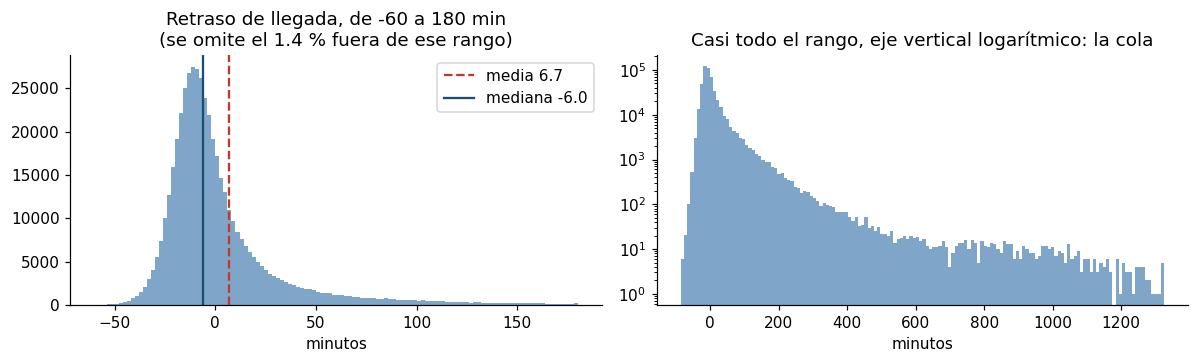

In [11]:
r = ent.loc[opera, Y]
q = r.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(1)
resumen_y = pd.Series({
    "media": r.mean(), "mediana": r.median(), "desviación estándar": r.std(),
    "mínimo": r.min(), "máximo": r.max(), "asimetría": r.skew(),
    f"% con más de {UMBRAL_RETRASO} min": 100 * (r > UMBRAL_RETRASO).mean(),
    "% que llegó antes (retraso < 0)": 100 * (r < 0).mean(),
    "% con más de 180 min (3 h)": 100 * (r > 180).mean(),
    "vuelos con más de 600 min (10 h)": float((r > 600).sum()),
}).round(2)
display(resumen_y.to_frame("valor"))
display(q.to_frame("percentil").T.rename(columns=lambda p: f"p{int(p * 100)}"))

lo, hi = -60, 180
dentro = r[r.between(lo, hi)]
tope = r.quantile(0.9999)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(dentro, bins=120, color="#7fa6c9")
ax[0].axvline(r.mean(), color="#c0392b", ls="--", label=f"media {r.mean():.1f}")
ax[0].axvline(r.median(), color="#1b4f72", ls="-", label=f"mediana {r.median():.1f}")
ax[0].set_title(f"Retraso de llegada, de {lo} a {hi} min\n(se omite el {100 * (1 - len(dentro) / len(r)):.1f} % fuera de ese rango)")
ax[0].set_xlabel("minutos"); ax[0].legend()
ax[1].hist(r[r <= tope], bins=150, color="#7fa6c9")
ax[1].set_yscale("log"); ax[1].set_title("Casi todo el rango, eje vertical logarítmico: la cola")
ax[1].set_xlabel("minutos")
plt.tight_layout(); plt.show()

**Qué significa esto para el resto del proyecto:**

- La mediana queda **por debajo** de la media y la asimetría es muy alta: es una **cola larga a la derecha**. Unos pocos vuelos con muchas horas de retraso pesan mucho en el RMSE, mientras que el MAE casi no los nota. Por eso se miden **los dos**: MAE dice el error típico; RMSE castiga los errores grandes.
- Una parte grande de los vuelos llega **antes** de lo programado (retraso negativo): el logaritmo directo no sirve. Cómo transformar la etiqueta se resuelve en el notebook 02, comparando alternativas con validación cruzada.
- Hay vuelos con retrasos de **decenas de horas**. ¿Son errores de captura o vuelos reales (tormentas, fallas)? Es una decisión de limpieza del notebook 02, no de este.

### ¿Cambia el retraso en el tiempo y según el vuelo?

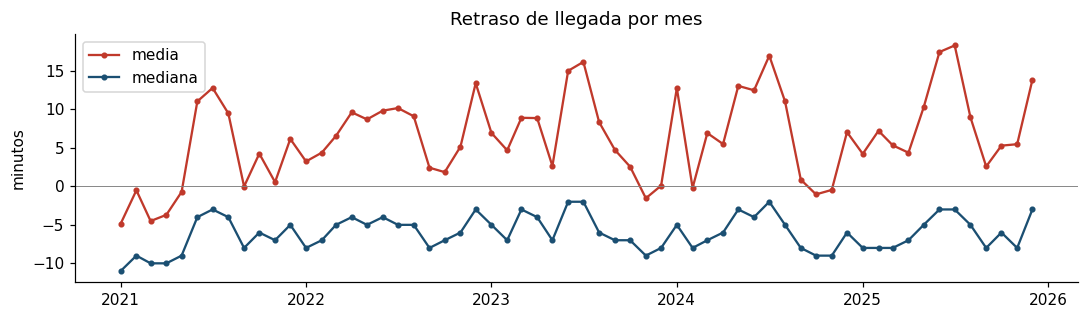

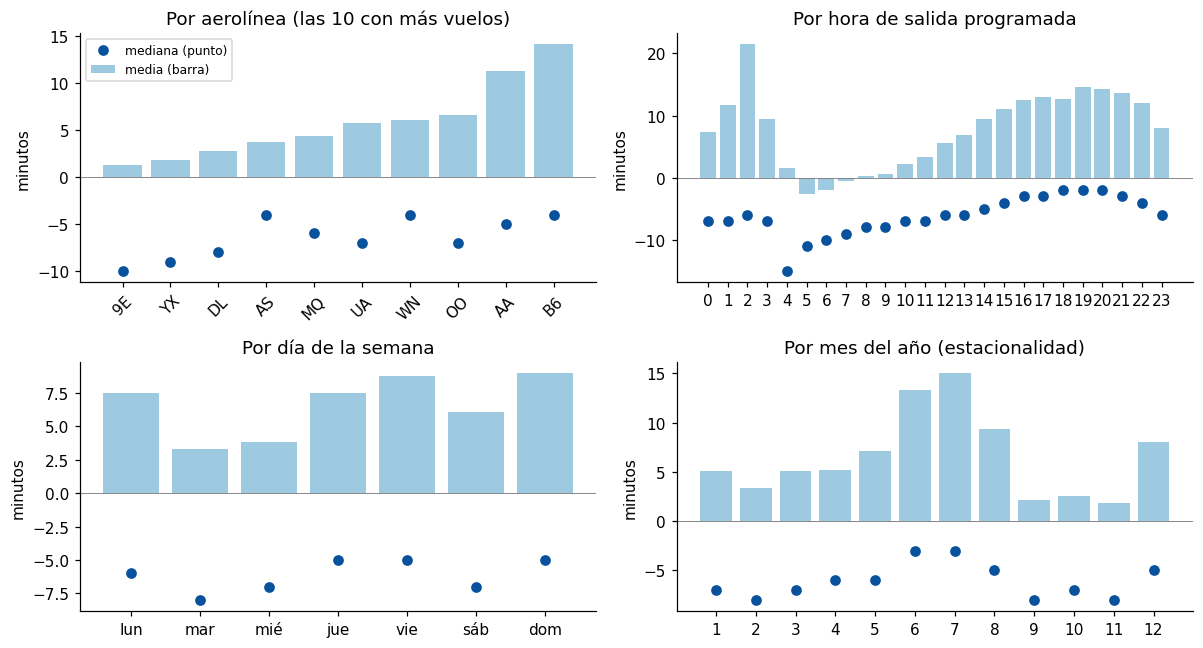

In [12]:
base = ent.loc[opera].copy()
if ROLES["hora_prog_salida"]:
    base["hora"] = (pd.to_numeric(base[ROLES["hora_prog_salida"]], errors="coerce") // 100).clip(0, 23)
base["dia_semana"] = base["fecha"].dt.dayofweek
base["mes_del_anio"] = base["fecha"].dt.month

# --- tendencia en el tiempo ---
mensual = base.groupby(base["fecha"].dt.to_period("M"))[Y].agg(["mean", "median", "count"])
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(mensual.index.to_timestamp(), mensual["mean"], marker="o", ms=3, label="media", color="#c0392b")
ax.plot(mensual.index.to_timestamp(), mensual["median"], marker="o", ms=3, label="mediana", color="#1b4f72")
ax.axhline(0, color="gray", lw=0.6); ax.set_ylabel("minutos"); ax.legend()
ax.set_title("Retraso de llegada por mes"); plt.tight_layout(); plt.show()

# --- patrones por grupo ---
def barras(ax, g, titulo, etiquetas=None, rot=0):
    ax.bar(range(len(g)), g["mean"], color="#9ecae1", label="media (barra)")
    ax.plot(range(len(g)), g["median"], "o", color="#08519c", label="mediana (punto)")
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels(etiquetas if etiquetas is not None else list(g.index), rotation=rot)
    ax.axhline(0, color="gray", lw=0.6); ax.set_title(titulo); ax.set_ylabel("minutos")

def resumen_grupo(columna):
    return base.groupby(columna)[Y].agg(["mean", "median"])

fig, axs = plt.subplots(2, 2, figsize=(11, 6))
if ROLES["aerolinea"]:
    top = base[ROLES["aerolinea"]].value_counts().head(10).index
    g = base[base[ROLES["aerolinea"]].isin(top)].groupby(ROLES["aerolinea"])[Y].agg(["mean", "median"]).sort_values("mean")
    barras(axs[0, 0], g, "Por aerolínea (las 10 con más vuelos)", rot=45)
    axs[0, 0].legend(loc="upper left", fontsize=8)
else:
    axs[0, 0].axis("off")
if ROLES["hora_prog_salida"]:
    g = resumen_grupo("hora")
    barras(axs[0, 1], g, "Por hora de salida programada", etiquetas=[int(h) for h in g.index])
else:
    axs[0, 1].axis("off")
barras(axs[1, 0], resumen_grupo("dia_semana"), "Por día de la semana",
       etiquetas=["lun", "mar", "mié", "jue", "vie", "sáb", "dom"])
barras(axs[1, 1], resumen_grupo("mes_del_anio"), "Por mes del año (estacionalidad)")
plt.tight_layout(); plt.show()

**Lo que se observa:** el retraso tiene un **ciclo anual** (peor en verano y en diciembre), empeora a lo largo del día (las salidas de la tarde y la noche acumulan los retrasos de las anteriores) y varía entre aerolíneas. Son patrones reales y estables, así que hay algo que aprender. Pero fíjense en la escala: las diferencias entre grupos son de unos pocos minutos, y la dispersión del retraso individual es mucho mayor. Eso anticipa que **las reglas por grupo mejorarán poco** a la línea base.

### ¿Por qué importa tanto el momento de predicción?

Si el retraso de salida estuviera disponible, casi lo explicaría todo. Pero **solo se conoce cuando el avión ya salió**. Con `MOMENTO_PREDICCION = "programacion"`, esa columna **no puede ser entrada del modelo**: sería una fuga, como `decision_renovacion` en seguros.

In [13]:
if ROLES["retraso_salida"]:
    par = pd.concat([pd.to_numeric(base[ROLES["retraso_salida"]], errors="coerce"), base[Y]], axis=1).dropna()
    rho = par.corr().iloc[0, 1]
    print(f"Correlación entre el retraso de salida y el de llegada: {rho:.2f}  →  R² ≈ {rho ** 2:.2f}")
    print("Un modelo que la use parecería excelente. Pero ¿se conoce al programar el vuelo? No.")
    print(f"Momento elegido: «{MOMENTO_PREDICCION}».  Las columnas permitidas se fijan en el notebook 02.")
else:
    print("No se detectó la columna de retraso de salida; igual hay que decidir en el 02 cuáles se conocen a tiempo.")

Correlación entre el retraso de salida y el de llegada: 0.97  →  R² ≈ 0.94
Un modelo que la use parecería excelente. Pero ¿se conoce al programar el vuelo? No.
Momento elegido: «programacion».  Las columnas permitidas se fijan en el notebook 02.


## 6 · ¿Hace falta ML? Reglas a mano y línea base

Antes de entrenar nada: **una solución sin ML que sirva de punto de comparación.** Si un modelo no la supera, no vale la pena.

Se miden igual que se medirá a los modelos: **validación cruzada que respeta el tiempo** (`TimeSeriesSplit`): en cada ronda se aprende con lo anterior y se valida con el bloque siguiente. Las reglas de grupo usan solo información de la programación del vuelo (aerolínea, hora programada), así que son legales con `MOMENTO_PREDICCION = "programacion"`.

| Referencia | Qué predice |
|---|---|
| **Línea base** | siempre lo mismo: el promedio (o la mediana) del retraso |
| **Regla A** | el retraso típico de la aerolínea |
| **Regla B** | el retraso típico de la hora de salida programada (los retrasos se acumulan durante el día) |
| **Regla C** | el retraso típico de la aerolínea **en esa hora** |

Cada regla se evalúa con **media** (mejor para RMSE) y con **mediana** (mejor para MAE).

Validación cruzada temporal de 5 bloques sobre 490,242 vuelos de la muestra (408,535 validados) · minutos


,MAE,RMSE,R2
Línea base · promedio,26.509,59.277,-0.002
Línea base · mediana,24.025,60.765,-0.053
Regla A · aerolínea (mediana),23.946,60.758,-0.053
Regla B · hora (mediana),23.844,60.547,-0.045
Regla C · aerolínea × hora (mediana),23.733,60.538,-0.045
Regla A · aerolínea (promedio),26.442,59.202,0.001
Regla B · hora (promedio),26.058,58.971,0.008
Regla C · aerolínea × hora (promedio),26.002,59.014,0.007


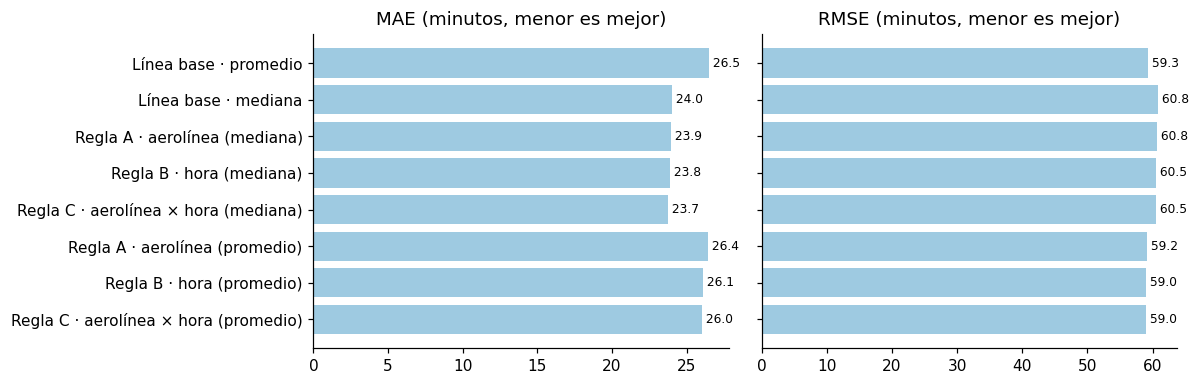

Mejor referencia por métrica:
  MAE     23.733   (Regla C · aerolínea × hora (mediana))
  RMSE    58.971   (Regla B · hora (promedio))
  R2       0.008   (Regla B · hora (promedio))
Frente a la línea base, la mejor regla mejora el MAE en 1.2% y el RMSE en 0.5%.
▶ Número a vencer: MAE < 23.73 min · RMSE < 58.97 min · R² > 0.008


In [14]:
base = base.sort_values("fecha", kind="stable").reset_index(drop=True)
tscv = TimeSeriesSplit(n_splits=5)

def constante(estadistico):
    return lambda tr, va: np.full(len(va), getattr(tr[Y], estadistico)())

def por_grupo(cols, estadistico):
    def f(tr, va):
        g = tr.groupby(cols)[Y].agg(estadistico).rename("pred")
        p = va[cols].join(g, on=cols)["pred"]
        return p.fillna(getattr(tr[Y], estadistico)()).to_numpy()
    return f

def evaluar(predictor):
    reales, preds = [], []
    for i_tr, i_va in tscv.split(base):
        tr, va = base.iloc[i_tr], base.iloc[i_va]
        preds.append(predictor(tr, va)); reales.append(va[Y].to_numpy())
    reales, preds = np.concatenate(reales), np.concatenate(preds)
    return {"MAE": mean_absolute_error(reales, preds),
            "RMSE": float(np.sqrt(mean_squared_error(reales, preds))),
            "R2": r2_score(reales, preds)}

reglas = {"Línea base · promedio": constante("mean"), "Línea base · mediana": constante("median")}
AER, HORA = ROLES["aerolinea"], ("hora" if ROLES["hora_prog_salida"] else None)
for est, nombre in (("median", "mediana"), ("mean", "promedio")):
    if AER:           reglas[f"Regla A · aerolínea ({nombre})"] = por_grupo([AER], est)
    if HORA:          reglas[f"Regla B · hora ({nombre})"] = por_grupo([HORA], est)
    if AER and HORA:  reglas[f"Regla C · aerolínea × hora ({nombre})"] = por_grupo([AER, HORA], est)

tabla_reglas = pd.DataFrame({k: evaluar(v) for k, v in reglas.items()}).T
n_val = sum(len(i_va) for _, i_va in tscv.split(base))
print(f"Validación cruzada temporal de 5 bloques sobre {len(base):,} vuelos de la muestra ({n_val:,} validados) · minutos")
display(tabla_reglas.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
orden = tabla_reglas.index[::-1]
for a, m in zip(ax, ["MAE", "RMSE"]):
    a.barh(orden, tabla_reglas.loc[orden, m], color="#9ecae1"); a.set_title(m + " (minutos, menor es mejor)")
    for i, v in enumerate(tabla_reglas.loc[orden, m]):
        a.text(v, i, f" {v:.1f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

META = {"MAE": float(tabla_reglas["MAE"].min()), "RMSE": float(tabla_reglas["RMSE"].min()),
        "R2": float(tabla_reglas["R2"].max())}
MEJOR = {"MAE": tabla_reglas["MAE"].idxmin(), "RMSE": tabla_reglas["RMSE"].idxmin(), "R2": tabla_reglas["R2"].idxmax()}
base_mae, base_rmse = tabla_reglas.loc["Línea base · mediana", "MAE"], tabla_reglas.loc["Línea base · promedio", "RMSE"]
mejora_mae, mejora_rmse = 1 - META["MAE"] / base_mae, 1 - META["RMSE"] / base_rmse
print("Mejor referencia por métrica:")
for m in ("MAE", "RMSE", "R2"):
    print(f"  {m:<5} {META[m]:>8.3f}   ({MEJOR[m]})")
print(f"Frente a la línea base, la mejor regla mejora el MAE en {mejora_mae:.1%} y el RMSE en {mejora_rmse:.1%}.")
print(f"▶ Número a vencer: MAE < {META['MAE']:.2f} min · RMSE < {META['RMSE']:.2f} min · R² > {META['R2']:.3f}")

### Cómo leer esta tabla

- **Las reglas de mediana tienen R² negativo, y es normal.** La mediana minimiza el error absoluto (MAE), no el cuadrático: al ser la etiqueta tan asimétrica, la mediana queda lejos de la media y el R² sale negativo. Las reglas de promedio sí compiten en RMSE y R². Por eso la meta se fija **métrica por métrica**, con la mejor referencia de cada una.
- El **R² de las reglas es muy bajo** (cercano a cero): con solo aerolínea y hora se explica una porción mínima de la variación del retraso. Esa es la dificultad real del problema, no un error.
- Si la regla C no mejora a la A o a la B, la combinación aerolínea × hora **no aporta**.
- Un modelo con ML tiene que **superar estas filas**, no el cero. Si lo único que logra es un R² parecido, no justifica su complejidad.

## 7 · Veredicto: ¿vale la pena probar ML?

La misma lista de chequeo de la sesión 6, respondida con los números de este mismo notebook (la tabla se arma sola con lo que se calculó arriba).

In [15]:
def rango(serie):
    return f"{serie.min():.1f} a {serie.max():.1f}"

g_mes = base.groupby("mes_del_anio")[Y].mean()
trozos_patron = []
if ROLES["aerolinea"]:
    top = base[ROLES["aerolinea"]].value_counts().head(10).index
    trozos_patron.append(f"de {rango(base[base[ROLES['aerolinea']].isin(top)].groupby(ROLES['aerolinea'])[Y].mean())} min según la aerolínea")
if ROLES["hora_prog_salida"]:
    trozos_patron.append(f"de {rango(base.groupby('hora')[Y].mean())} min según la hora de salida programada")
trozos_patron.append(f"de {rango(g_mes)} min según el mes del año")
patron = "El retraso medio va " + ", ".join(trozos_patron) + f". Pero la desviación estándar del retraso individual es de {r.std():.0f} min."

if mejora_mae < 0.10 and META["R2"] < 0.10:
    regla = (f"**No basta.** La mejor regla mejora la línea base solo {mejora_mae:.1%} en MAE y {mejora_rmse:.1%} en RMSE "
             f"(R² máximo {META['R2']:.3f}). Con información de la programación, el retraso es difícil de predecir: hay margen para ML, pero es estrecho.")
else:
    regla = (f"**Parcialmente.** La mejor regla mejora la línea base {mejora_mae:.1%} en MAE y {mejora_rmse:.1%} en RMSE "
             f"(R² máximo {META['R2']:.3f}); un modelo debe superarla de forma clara.")

display(Markdown(f"""
| Pregunta | Respuesta |
|---|---|
| **¿Hay un patrón que aprender?** | Sí, pero débil frente al ruido. {patron} |
| **¿Hay etiqueta?** | Sí: el retraso de llegada, en los vuelos que llegaron ({opera.mean():.1%} del entrenamiento). Los cancelados y desviados no aplican y quedan fuera. |
| **¿Hay suficientes datos?** | Sí: {N_FILAS['train']:,} vuelos de entrenamiento entre {ent_min:%Y-%m} y {ent_max:%Y-%m}, y {N_FILAS['test']:,} de prueba. Alcanzan para ensambles de árboles; los métodos basados en distancias y las redes se entrenarán con submuestras. |
| **¿Una regla a mano ya basta?** | {regla} |
| **¿Cuánto cuesta equivocarse?** | Depende del tamaño del error: 10 minutos casi no afectan a un pasajero; 2 horas hacen perder conexiones. Por eso se miden MAE (error típico) y RMSE (castiga los errores grandes). |

**Veredicto: sí vale la pena probar ML**, con una meta clara y modesta: **MAE < {META['MAE']:.2f} min, RMSE < {META['RMSE']:.2f} min y R² > {META['R2']:.3f}**
(las mejores referencias a mano). Con información de la programación se espera una mejora pequeña; lo importante es medirla bien: validación que respete el tiempo y prueba sin tocar.
"""))


| Pregunta | Respuesta |
|---|---|
| **¿Hay un patrón que aprender?** | Sí, pero débil frente al ruido. El retraso medio va de 1.3 a 14.1 min según la aerolínea, de -2.6 a 21.4 min según la hora de salida programada, de 1.8 a 15.0 min según el mes del año. Pero la desviación estándar del retraso individual es de 57 min. |
| **¿Hay etiqueta?** | Sí: el retraso de llegada, en los vuelos que llegaron (98.0% del entrenamiento). Los cancelados y desviados no aplican y quedan fuera. |
| **¿Hay suficientes datos?** | Sí: 35,887,876 vuelos de entrenamiento entre 2021-01 y 2025-12, y 3,185,124 de prueba. Alcanzan para ensambles de árboles; los métodos basados en distancias y las redes se entrenarán con submuestras. |
| **¿Una regla a mano ya basta?** | **No basta.** La mejor regla mejora la línea base solo 1.2% en MAE y 0.5% en RMSE (R² máximo 0.008). Con información de la programación, el retraso es difícil de predecir: hay margen para ML, pero es estrecho. |
| **¿Cuánto cuesta equivocarse?** | Depende del tamaño del error: 10 minutos casi no afectan a un pasajero; 2 horas hacen perder conexiones. Por eso se miden MAE (error típico) y RMSE (castiga los errores grandes). |

**Veredicto: sí vale la pena probar ML**, con una meta clara y modesta: **MAE < 23.73 min, RMSE < 58.97 min y R² > 0.008**
(las mejores referencias a mano). Con información de la programación se espera una mejora pequeña; lo importante es medirla bien: validación que respete el tiempo y prueba sin tocar.


## 8 · Guardar lo que necesitan los demás notebooks

In [16]:
resumen = {
    "pregunta": "minutos de retraso en la llegada (regresión)",
    "momento_prediccion": MOMENTO_PREDICCION,
    "semilla": SEED,
    "roles": ROLES, "partes_fecha": PARTES_FECHA, "formato_fecha_por_archivo": FORMATO_POR_ARCHIVO,
    "fecha_corte": FECHA_CORTE,
    "n_archivos": len(archivos), "n_filas_total": int(sum(filas_parquet.values())),
    "n_train": N_FILAS["train"], "n_test": N_FILAS["test"], "n_muestra": len(ent),
    "rango_train": [str(ent_min.date()), str(ent_max.date())],
    "rango_test": [str(pru_min.date()), str(pru_max.date())],
    "tipos": TIPOS,
    "fechas": {"filas_por_metodo": {k: int(v) for k, v in por_metodo.items()}, "sin_resolver": n_sin},
    "descartadas_sin_fecha": N_FILAS["sin_fecha"],
    "lineas_base": tabla_reglas.round(4).to_dict(orient="index"),
    "meta": META, "mejor_referencia": MEJOR,
}
with open(INTERIM / "resumen_01.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, ensure_ascii=False, indent=2, default=str)
print("Guardado:", INTERIM / "resumen_01.json")
for p in (MENSUAL, TRAIN, TEST):
    print(f"  {p}: {len(list(p.glob('*.parquet')))} archivos")
print("  ", INTERIM / "train_muestra.parquet")

Guardado: ../data/interim/resumen_01.json
  ../data/interim/mensual: 65 archivos
  ../data/interim/train: 60 archivos
  ../data/interim/test: 5 archivos
   ../data/interim/train_muestra.parquet


## Lo que deja este notebook

1. **Una pregunta bien definida:** retraso de llegada en minutos, con el **momento de predicción** declarado (qué se conoce y cuándo).
2. **Datos leídos sin trampas:** fechas con formato verificado, «NA» conservado, códigos tratados como texto, todo lo no numérico en columnas numéricas contado.
3. **Partición temporal** hecha antes de medir nada; **la prueba queda guardada** hasta el notebook 05.
4. **El número a vencer:** la mejor regla a mano, con MAE, RMSE y R² medidos con validación cruzada temporal.

**Antes de pasar al notebook 02**

- [ ] Completaron la licencia y la fecha de descarga en la tabla de la fuente.
- [ ] Revisaron `docs/diccionario_borrador.csv`, sobre todo `momento_en_que_se_conoce` (viene pre-llenado según la documentación del BTS): de ahí sale la lista de fugas.
- [ ] `Restart & Run All` corre de principio a fin sin errores.

**Siguiente:** `02_limpieza` — duplicados, valores imposibles, cómo transformar la etiqueta (cola larga y negativos) y el descarte de columnas con fuga.